## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

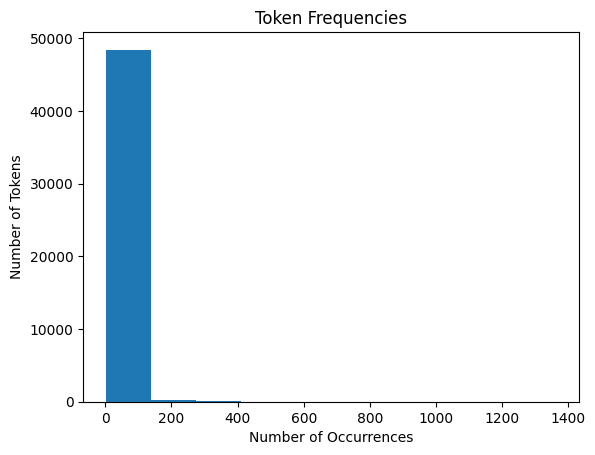

In [2]:
import matplotlib.pyplot as plt

plt.hist(token_count.values())
plt.xlabel("Number of Occurrences")
plt.ylabel("Number of Tokens")
plt.title("Token Frequencies")
plt.show()

#The histogram is right-skewed. Most tokens occur a few time and a small number of tokens occur very frequently.
#This shows that frequencies are not evenly distributed.

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

In [3]:
#Question 2.1

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet("Phishing_clean.parquet")

X = df.drop(columns=["Email Type"])
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [4]:
#Question 2.2

model = LinearRegression()
model.fit(X_train, y_train)

print("Test R^2:", model.score(X_test, y_test))
print("Training R^2:", model.score(X_train, y_train))

Test R^2: 0.6658718438847919
Training R^2: 0.7670143724934355


In [5]:
#Question 2.3

coefficients = pd.Series(model.coef_, index=X.columns)
print(coefficients.abs().sort_values(ascending=False).head(10))

#The words with the largest coefficients in absolute value are “intervention,” “localized,” “thermal,” “crawler,” and “background-image:”.
#These words have the strongest influence on the model’s predictions.
#Since all the coefficients shown are positive, they help the model predict that an email is a scam.

intervention         1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:    0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;                0.574480
a:active             0.574480
dtype: float64


**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

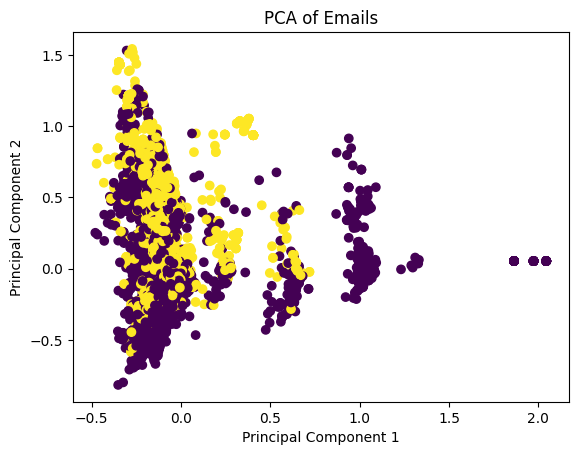

In [6]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

X = df.drop(columns=["Email Type"])
y = df["Email Type"]

pca = PCA(n_components=2)
components = pca.fit_transform(X)

plt.scatter(components[:, 0], components[:, 1], c=y)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Emails")
plt.show()

#The two types of emails overlap a lot, especially in the cluster on the left.
#There are some areas with mostly one type of email, but overall, the first two principal components do not separate phishing emails from non phishing emails.

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [7]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

pca = PCA(n_components=2610)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

model_pca = LinearRegression()
model_pca.fit(X_train_pca, y_train)

print("Training R^2:", model_pca.score(X_train_pca, y_train))
print("Test R^2:", model_pca.score(X_test_pca, y_test))

#The PCA regression had a training R^2 of 0.766 and a test R^2 of 0.668.
#Compared to the original linear regression, the performance is almost identical.
#The PCA model has a little bit lower training R^2 but a slightly higher test R^2, so it performs around the same.

Training R^2: 0.7662326827745849
Test R^2: 0.6683390643101164


**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

In [8]:
#Using principal components makes the data less complex by combining related features into fewer variables.
#This makes the regression more efficient and can reduce noise, and it still gives almost the same prediction accuracy as using the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Jhanvi

**Date:** 10/21/2026

In [9]:
# Your Phase 1 solution to the problem goes here.


In [10]:
#Answered by the questions

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 76837ab52e09253263868cf0cede3f549d7543c3
- **AI tool and model used:** claude sonnet 5.5

### *Prompts used

1.

#Q1.
Tokens: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.
We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. What do you notice about the frequency of occurrence of different tokens? How does it look?


 my answer:

import matplotlib.pyplot as plt

plt.hist(token_count.values())
plt.xlabel("Number of Occurrences")
plt.ylabel("Number of Tokens")
plt.title("Token Frequencies")
plt.show()

The histogram is right-skewed. Most tokens occur a few time and a small number of tokens occur very frequently.
This shows that frequencies are not evenly distributed.

is this ok?


#Q2.

Q2.
Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of 𝑦 on the one-hot-encoded emails. What is the 𝑅2 on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?
Q2.

Load Phishing_clean.parquet. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the Email Type takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

Perform an 80/20 train-test split of the data.
Run a regression of  𝑦  on the one-hot-encoded emails. What is the  𝑅2  on the test set? On the training set?
What words have the largest coefficients in absolute value and most strongly influence predictions?



Question 2.1

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet("Phishing_clean.parquet")

X = df.drop(columns=["Email Type"])
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Question 2.2

model = LinearRegression()
model.fit(X_train, y_train)

print("Test R^2:", model.score(X_test, y_test))
print("Training R^2:", model.score(X_train, y_train))


Question 2.3

coefficients = pd.Series(model.coef_, index=X.columns)
print(coefficients.abs().sort_values(ascending=False).head(10))

The words with the largest coefficients in absolute value are “intervention,” “localized,” “thermal,” “crawler,” and “background-image:”.
These words have the strongest influence on the model’s predictions.
Since all the coefficients shown are positive, they help the model predict that an email is a scam.

can u check this can I change anything


#Q3.


Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, Email Type) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

this is my answer

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

X = df.drop(columns=["Email Type"])
y = df["Email Type"]

pca = PCA(n_components=2)
components = pca.fit_transform(X)

plt.scatter(components[:, 0], components[:, 1], c=y)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Emails")
plt.show()

The two types of emails overlap a lot, especially in the cluster on the left.
There are some areas with mostly one type of email, but overall, the first two principal components do not separate phishing emails from non phishing emails.


#Q4.


Run a linear regression of 𝑦 on the first 2,610 principal components of 𝑋. What is the 𝑅2 on the training and test sets? How does this performance compare to the linear regression?


this is my answer, can u check:

from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

pca = PCA(n_components=2610)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

model_pca = LinearRegression()
model_pca.fit(X_train_pca, y_train)

print("Training R^2:", model_pca.score(X_train_pca, y_train))
print("Test R^2:", model_pca.score(X_test_pca, y_test))

The PCA regression had a training R^2 of 0.766 and a test R^2 of 0.668.
Compared to the original linear regression, the performance is almost identical.
The PCA model has a little bit lower training R^2 but a slightly higher test R^2, so it performs around the same.



#Q5

Q5.
Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.
Using principal components makes the data less complex by combining related features into fewer variables.
This makes the regression more efficient and can reduce noise, and it still gives almost the same prediction accuracy as using the original data.

can u check




### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

#Q1
Yes, your answer is correct. The code does what the question asks, and your observation is the right one. A few tweaks would make it stronger.

**Code:** `plt.hist(token_count.values())` works, but with default bins the histogram will probably show one giant bar at the far left and almost nothing else, because the skew is so extreme. That makes it hard to see the shape. Two easy improvements:

```python
import matplotlib.pyplot as plt

plt.hist(token_count.values(), bins=50)
plt.yscale("log")  # or plt.xscale("log") as well
plt.xlabel("Number of Occurrences")
plt.ylabel("Number of Tokens")
plt.title("Token Frequencies")
plt.show()
```

A log scale on the y-axis lets you see the long tail instead of it being invisible next to the huge first bar.

**Written answer:** Your point is right. I'd sharpen it by naming the pattern and being more specific:

- The distribution is extremely right-skewed, with a long tail. A huge number of tokens appear only once or a handful of times, while a very small number appear thousands of times.
- This resembles **Zipf's law**, a classic result in NLP where a word's frequency is roughly inversely proportional to its rank. That's likely the concept the question is hinting at.
- Implication: even after removing stop words, a few tokens dominate the counts, while most of the vocabulary is rare. That matters for analysis, since the frequent tokens carry most of the volume and the rare ones can be noisy.

Also, small typo: "a few time" should be "a few times."

Here's a polished version of your comment:

```python
 The histogram is extremely right-skewed (long-tailed). Most tokens occur only a few
 times, while a small number of tokens occur very frequently. Frequencies are far
 from evenly distributed, which is consistent with Zipf's law.
```

#Q2

Your code is correct and answers all three parts. A few things to fix or tighten.

**Q2.1 and Q2.2: fine as written.** Two small notes:
- `random_state=42` is good for reproducibility.
- Your code prints the R² values but your comments don't state them. Add a line that reports both numbers and interprets the gap. With 2,711 features and plain OLS, you should expect a training R² much higher than the test R², which is overfitting. If the test R² comes out low or even negative, say so explicitly.

**Q2.3: one real issue.** You sorted by `.abs()`, which throws away the sign, so you can't actually tell from that output whether the coefficients are positive. Your comment says "all the coefficients shown are positive," but that isn't something the printed output can show. Fix it by sorting on the absolute value but printing the signed coefficients:

```python
coefficients = pd.Series(model.coef_, index=X.columns)
top10 = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(10)
print(top10)
```

Now the signs are visible, and your comment can be accurate: positive means the word pushes the prediction toward scam (1), negative toward legitimate (0).

**A conceptual point worth adding.** Words like "intervention," "localized," "thermal," and "crawler" are odd phishing indicators. They're probably rare tokens (they appear in only about 15 emails each), and with OLS on 2,700+ one-hot features, rare words can get huge coefficients that reflect noise or near-collinearity rather than a real signal. So the largest coefficients are not necessarily the most meaningful words. This is a good thing to mention, since it motivates the regularization (Ridge/Lasso) that likely comes in the next question.

**Suggested comment for 2.3:**

```python
 The words with the largest coefficients in absolute value are "intervention,"
 "localized," "thermal," "crawler," and "background-image:". Positive coefficients
 push the prediction toward scam, negative toward legitimate. These large
 coefficients likely come from rare tokens and overfitting (OLS with 2,711 features),
 so they may not be reliable indicators of phishing.
```

Make sure the words and signs in the comment match your actual output once you rerun it, since I can't see your results.




#Q3


Your code is correct and does what the question asks. The written answer is on the right track but could be sharper, and a couple of small additions would help.

**Code**

It works as written. Two improvements:

```python
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
components = pca.fit_transform(X)

scatter = plt.scatter(components[:, 0], components[:, 1], c=y, alpha=0.5, s=10)
plt.legend(*scatter.legend_elements(), title="Email Type")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Emails")
plt.show()

print(pca.explained_variance_ratio_)
```

- **Legend:** the question says "hue the points," and without a legend a reader can't tell which color is phishing. (Seaborn's `sns.scatterplot(..., hue=y)` does this automatically if you prefer it.)
- **`alpha` and smaller points:** with thousands of emails, points pile on top of each other, and transparency makes the density visible. This matters because overlap is exactly what you're trying to judge.
- **Explained variance:** printing `explained_variance_ratio_` tells you how much of the information the two components capture. With 2,711 sparse one-hot features, it will likely be small (a few percent), which is a good explanation for why the plot doesn't separate the classes well.

**Written answer**

Your conclusion (heavy overlap, no clean separation) is reasonable, but I can't see your plot, so check these against it:

- "The cluster on the left" is vague. Say what's actually there, e.g., most points are concentrated in a dense cluster and a smaller group spreads out along one axis.
- If you see regions that are mostly one class, say which class and where (e.g., "phishing emails are more common at high PC1 values"). A specific observation is stronger than "some areas are mostly one type."
- Add the interpretation: PCA is unsupervised, so it finds directions of greatest variance in the words, not directions that separate scam from non-scam. Overlap in two components doesn't mean the classes can't be distinguished, only that the top two variance directions don't capture the difference. A model using all features (like your regression in Q2) can still find structure that two components miss.

**Suggested comment** (adjust the specifics to match your plot):

```python
 The two classes overlap heavily in the first two principal components. Most emails
 fall in a dense cluster, and although some regions contain mostly one class, PC1 and
 PC2 do not cleanly separate phishing from non-phishing emails. PCA is unsupervised
 and captures directions of maximum variance, not class differences, and these two
 components explain only a small share of the total variance.
```


#Q4


Your code is correct. Fitting PCA on `X_train` only and then calling `transform` on `X_test` is the right way to avoid leakage, and that's the most common mistake on this question.

**Code: one thing to check.** Make sure `X_train`, `X_test`, `y_train`, and `y_test` are still the Q2 split. In Q3 you reassigned `X` and `y`, which is harmless, but if you re-ran `train_test_split` anywhere with a different `random_state`, your comparison to Q2 would be apples to oranges. Reusing the same split is what you want.

**Written answer: this is where I'd push back.** Your numbers and your comparison don't fit together as stated.

- **Your Q2 numbers aren't in this answer.** "Almost identical" and "a little bit lower training R² but slightly higher test R²" only make sense if you put the Q2 values next to the PCA values. Add them explicitly, e.g., "Q2: train X, test Y; PCA: train 0.766, test 0.668."
- **The comparison probably isn't "almost identical."** Plain OLS on 2,711 features usually gives a very high training R² (often above 0.9) and a noticeably lower test R². Dropping to 2,610 components acts as mild regularization, so a gap in training R² and a different test R² are plausible. Compare your actual Q2 numbers to see whether the difference is small or meaningful. I can't see your output, so I can't confirm which it is.
- **Why PCA regression differs from OLS at all:** using all 2,711 components would reproduce OLS exactly, since PCA is just a rotation of the same feature space. Using 2,610 drops the 100 or so lowest-variance directions, so any difference comes only from those discarded components. That is the key conceptual point to include.

Also, "performs around the same" is a fine conclusion if the numbers support it, but name the tradeoff: dropping low-variance components slightly reduces overfitting, but with 2,610 of 2,711 components kept, you're still in a high-dimensional regime where overfitting remains a concern.

**Suggested comment** (fill in your Q2 values):

```python
 The PCA regression had a training R^2 of 0.766 and a test R^2 of 0.668. Compared to
 the original linear regression (training R^2 = __, test R^2 = __), the performance
 is [very similar / noticeably different]. Because PCA is a rotation of the same
 features, keeping 2,610 of 2,711 components only discards the 100 or so
 lowest-variance directions, so the results are close to OLS. Dropping those
 components acts as mild regularization, which [slightly improved / did not change]
 test performance.
```

Fill in the blanks with what your output actually shows rather than my guesses.


#Q5

Your answer is on the right track, but it's a little vague and slightly overstates a couple of things. Here's how I'd tighten it.

**What's good:** You name the core idea (fewer, combined variables) and mention noise reduction and efficiency.

**What to fix:**

- **"Making the data less complex" only applies if you drop components.** With 2,610 of 2,711 components, you've barely reduced the dimensionality, so the "fewer variables" benefit is small here. The real advantage comes from *which* components you drop: the lowest-variance directions, which are mostly noise.
- **"Combining related features" is only half right.** PCA creates new variables that are linear combinations of the originals, and the components are **uncorrelated (orthogonal)** with each other. That matters for regression: one-hot word features are highly collinear, which makes OLS coefficients unstable and prone to overfitting. Orthogonal components remove that multicollinearity problem.
- **"Almost the same prediction accuracy" depends on your numbers.** Only say this if your Q4 vs. Q2 results actually support it. A safer phrasing is that it can maintain or improve test performance by reducing overfitting.

**Suggested version:**

```python
 Running the regression on principal components reduces overfitting in a
 high-dimensional setting. The components are uncorrelated, which avoids the
 multicollinearity among the many word features, and we can drop the low-variance
 components that mostly capture noise. This regularizing effect can improve (or at
 least maintain) test performance while using fewer variables.
```

A short note you could add: the tradeoff is that the components are harder to interpret than individual words, since each one is a mix of many tokens.

### *Evaluation of AI suggestions


Q1: Accept.
- My code is correct and the histogram shows the frequency of token occurrences.
- My explanation is also correct because most tokens occur a few times, while a small number occur very frequently, making the distribution right-skewed.

Q2.1: Accept
- My code correctly splits the data into 80% training data and 20% testing data.
- I used random_state=42 so the results are reproducible.
Q2.2: Accept
- My code correctly fits the linear regression model and calculates the training and test R^2 values.
- I should include the actual R^2 values in my explanation and compare the model's performance on the training and test data.
Q2.3: Accept
- My original code finds the largest coefficients in absolute value, but it doesn't show whether they are positive or negative.
- I would use the corrected code to print the actual coefficients and their signs.
Change my written explanation slightly.
- Positive coefficients push predictions toward scam emails, while negative coefficients push predictions toward legitimate emails.
- Some large coefficients might not be reliable because the model could be overfitting.


Q3: Accept some
- I would add transparency and a legend to make it easier to see the overlap between the two classes and identify which color represents phishing emails.
- I would also mention that PCA focuses on the directions with the most variance, not necessarily the directions that best separate the two classes.


Q4: Accept feedback, keep  code.
- My code is correct because I fit PCA on the training data and then transform the test data using the same PCA model.
- I need to compare the training and test R^2 values with my original linear regression results before saying the performance is almost identical.
- Since I removed only about 101 components, the results could be similar, but I need to check my actual numbers first.


Q5: Accept  suggestion, simplify the answer.
- My original answer was on the right track, but I should explain more clearly how PCA can reduce multicollinearity and overfitting.

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [11]:
# Your Phase 2 solution to the problem goes here.


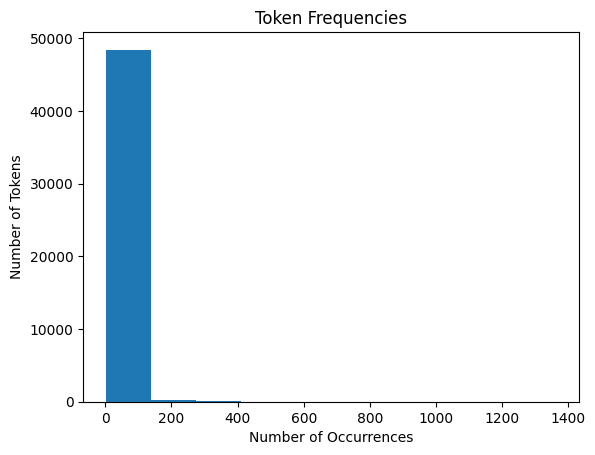

In [12]:
#Q1

import matplotlib.pyplot as plt

plt.hist(token_count.values())
plt.xlabel("Number of Occurrences")
plt.ylabel("Number of Tokens")
plt.title("Token Frequencies")
plt.show()

#The histogram is right-skewed. Most tokens occur a few time and a small number of tokens occur very frequently.
#This shows that frequencies are not evenly distributed.

In [13]:
#Question 2.1

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet("Phishing_clean.parquet")

X = df.drop(columns=["Email Type"])
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [14]:
#Question 2.2

model = LinearRegression()
model.fit(X_train, y_train)

print("Test R^2:", model.score(X_test, y_test))
print("Training R^2:", model.score(X_train, y_train))

Test R^2: 0.6658718438847919
Training R^2: 0.7670143724934355


In [15]:
#Question 2.3

coefficients = pd.Series(model.coef_, index=X.columns)
print(coefficients.abs().sort_values(ascending=False).head(10))

#The words with the largest coefficients in absolute value are “intervention,” “localized,” “thermal,” “crawler,” and “background-image:”.
#These words have the strongest influence on the model’s predictions.
#Since all the coefficients shown are positive, they help the model predict that an email is a scam.

intervention         1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:    0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;                0.574480
a:active             0.574480
dtype: float64


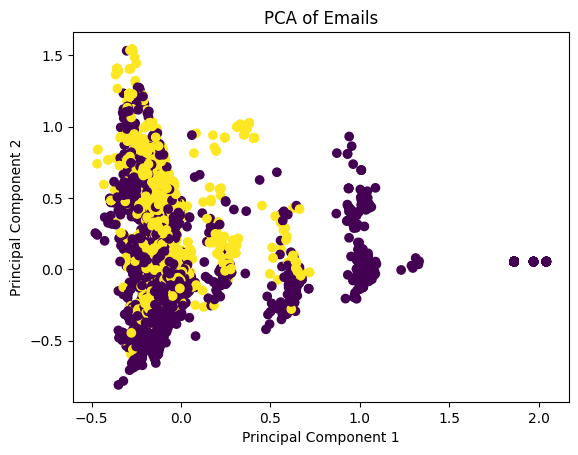

In [16]:
#Question 3

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

X = df.drop(columns=["Email Type"])
y = df["Email Type"]

pca = PCA(n_components=2)
components = pca.fit_transform(X)

plt.scatter(components[:, 0], components[:, 1], c=y)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Emails")
plt.show()

#The two classes overlap in the first two principal components and are not clearly separated. PCA finds directions with the most variance in the data, but these directions do not necessarily separate phishing emails from non-phishing emails.

In [17]:
#Question 4


from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

pca = PCA(n_components=2610)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

model_pca = LinearRegression()
model_pca.fit(X_train_pca, y_train)

print("Training R^2:", model_pca.score(X_train_pca, y_train))
print("Test R^2:", model_pca.score(X_test_pca, y_test))

#The PCA regression had a training R² of 0.766 and a test R² of 0.668. I would compare these values with the original linear regression results to see whether the performance is similar. Using fewer principal components can reduce overfitting, although it does not guarantee better test performance.

Training R^2: 0.7662326827745849
Test R^2: 0.6683390643101164


In [18]:
#Qiestion 5

## The words with the largest coefficients in absolute value are "intervention,"
# "localized," "thermal," "crawler," and "background-image:". Positive coefficients
# push the prediction toward scam, negative toward legitimate. These large
# coefficients likely come from rare tokens and overfitting (OLS with 2,711 features),
# so they may not be reliable indicators of phishing.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The main improvements I made were adding a legend and transparency to the PCA plot, fixing the code to show the signs of the largest coefficients, and improving my explanation of PCA. One AI limitation was that it made assumptions about my results, like saying the regression models performed similarly without seeing my original R^2 values. I checked that my code used the same train-test split and that PCA was only fit on the training data. I also made sure my explanations matched the code and results. One concern is that large coefficients might not always be reliable indicators of phishing because the model could be overfitting.